In [1]:
import functions as AvT
import xarray as xr
import numpy as np
import mne
from datetime import datetime
import os
import math

Optional: load TFR

In [2]:
directory_name = "labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr"

tfr_events = []

for f in os.scandir(f"output/{directory_name}"):
    if f.name.startswith("event"):
        tfr_events.append(mne.time_frequency.read_tfrs(f.path))
    if f.name.startswith("total"):
        tfr = mne.time_frequency.read_tfrs(f.path)
    

Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\event 0_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\event 1_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\event 2_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\event 3_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps

1. Collecting data

In [2]:
#parameters
ds_name = "labelled_data_200hz.nc"  #file name for the dataset
condition = "accuracy"              #condition [speed/accuracy]
force = "high"                      #force [high/low]
info_fname = "S1_epo.fif"

#create datasets
ds = xr.open_dataset(f"data/{ds_name}")
ds = ds.where(ds["condition"] == condition, drop=True)
ds = ds.where(ds["force"] == force, drop=True)
sfreq = ds.attrs['sfreq']

#create probabilities array
probs_shape = ds.probabilities.values.shape
probs = ds.probabilities.values.reshape(-1, probs_shape[2], probs_shape[3])

#create eeg array
eeg_shape = ds.data.values.shape
eeg = ds.data.values.reshape(-1, eeg_shape[2], eeg_shape[3])

#info object
info = mne.io.read_info(f"data/{info_fname}")

old_info = info.copy()

info = mne.create_info(
    ch_names=ds.channel.values.tolist(),
    sfreq=ds.attrs["sfreq"],
    ch_types="eeg",
)
with info._unlock():
    info["lowpass"] = float(ds.attrs["lowpass"])
    info["highpass"] = float(ds.attrs["highpass"])

montage = old_info.get_montage()
if montage is not None:
    info.set_montage(montage)

del ds #delete dataset to save memory

2. Preparing epochs

In [3]:
#parameters
n_trials = 500                 #n_trials for the TFR
batch_size = 500               #batch size for the processing of the TFRs

#filter valid trials
valid_trials = ~np.isnan(eeg[:, :, 0]).any(axis=1)
n_valid_trials = eeg[valid_trials].shape[0]
if n_valid_trials < n_trials:
    n_trials = n_valid_trials
    print(f"There are not enough valid trials to complete your request, we changed the number of trials to {n_valid_trials}")

#prepare epochs
eeg_batches = []

for batch in range(math.ceil(n_trials/batch_size)):
    lower = batch*batch_size
    upper = batch*batch_size+min(batch_size, n_trials-batch_size*batch)
    eeg_batches.append(eeg[valid_trials][lower:upper, :, :])

del eeg #delete eeg data to save memory

probs = (probs[valid_trials][:n_trials, :, :])

#create epochs
epochs_batches = []

for batch in eeg_batches:
    epochs_batches.append(mne.EpochsArray(np.nan_to_num(batch, nan=0.0), info, tmin=-0.2)) #navragen waarom er hier NaNs in zitten. Stimulus response based of HMP events based

Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated


3. Generating TFR events

In [4]:
#parameters
n_jobs = 1                                                              #parallel processes
baseline = (None, -0.15)                                                    #TFR baseline       
decim = 1 # wanneer gebeurt dit                                         #time compression
steps = 30                                                              #n_steps within the frequency interval
save = False                                                            #True if TFR are saved to .hdf5 files

low_freq = 2                                                            #lower bound frequency interval
high_freq = 40                                                          #higher bound frequency interval

low_cycle = 3                                                           #lower bound n_cycle interval
high_cycle = 8                                                          #higher bound n_cycle interval

t_left = 20                                                             #n_samples before the event onset
t_right = 20                                                            #n_samples after the event onset


#prepare TFR
freqs = list(np.logspace(np.log10(low_freq), np.log10(high_freq), steps)) #lees wat Irene en Mike doen
n_cycles = list(np.logspace(np.log10(low_cycle), np.log10(high_cycle), steps))

#generate TFR
for n, epochs in enumerate(epochs_batches):
    print(f"batch: {n+1}/{len(epochs_batches)}")
    if n == 0:
        tfr = AvT.get_tfr(epochs, freqs, baseline, jobs=n_jobs, decim=decim, cycles=n_cycles)
        tfr_events = AvT.get_tfr_events(tfr, probs, t_left, t_right, sfreq, decim=decim)
        tfr = tfr.average()
    else:
        temp_tfr = AvT.get_tfr(epochs, freqs, baseline, jobs=n_jobs, decim=decim, cycles=n_cycles)
        temp_tfr_events = AvT.get_tfr_events(temp_tfr, probs, t_left, t_right, sfreq, decim=decim)
        for n, temp_tfr_event in enumerate(temp_tfr_events):
            tfr_events[n].__add__(temp_tfr_event)
        temp_tfr = temp_tfr.average()
        tfr.__add__(temp_tfr)

tfr._data/(n_trials/batch_size) #get the average
for tfr_event in tfr_events:
    tfr_event._data/(n_trials/batch_size)

#save TFR
if save:
    directory_name = f"output/{ds_name} {condition} n_trials={n_trials} baseline={baseline} decim={decim} steps={steps} {datetime.today().strftime('%Y-%m-%d')}-tfr"
    os.mkdir(directory_name)

    tfr.save(f"{directory_name}/total_tfr.hdf5", overwrite=True)

    for n, tfr_event in enumerate(tfr_events):
        tfr_event.save(f"{directory_name}/event {n}_tfr.hdf5", overwrite=True)

batch: 1/1
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


retreiving TFR events
retreived TFR events succesfully


4. Plot TFR events

No baseline correction applied


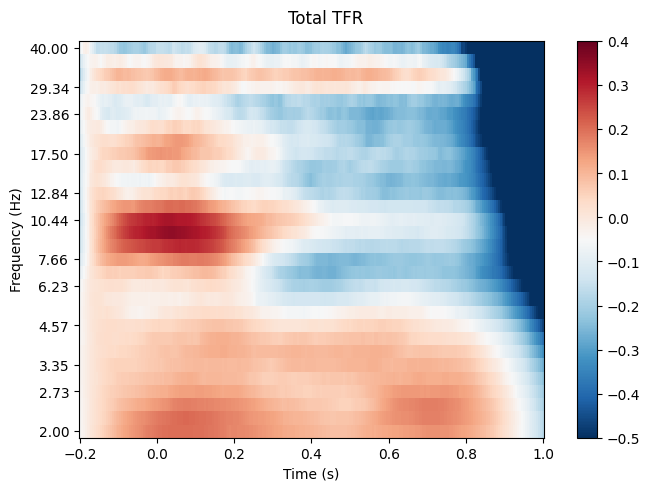

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


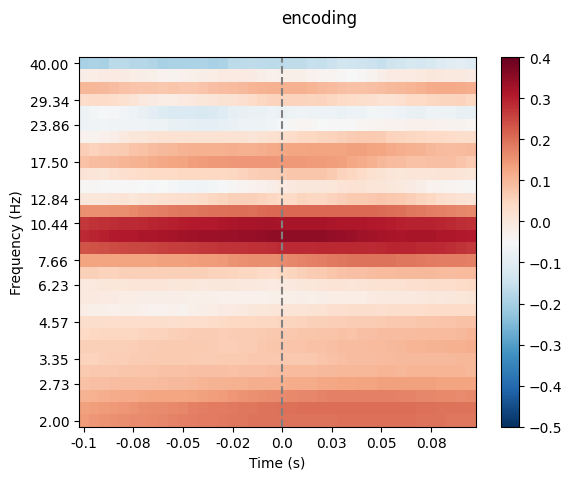

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


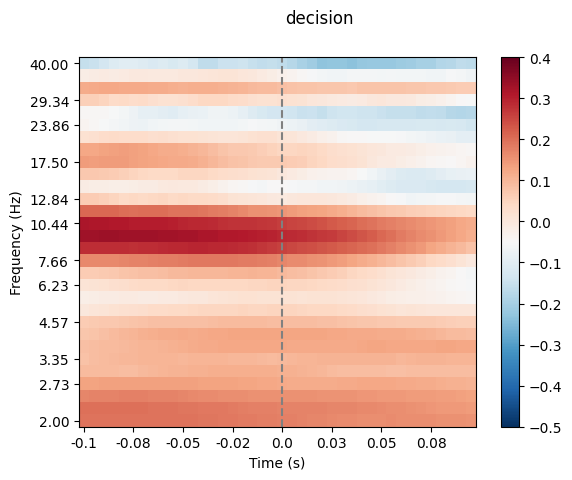

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


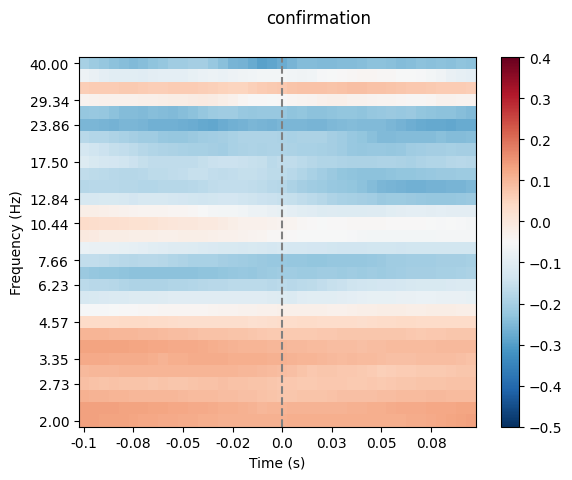

No baseline correction applied


c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\functions.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([round(x - t_event, 2) for x in ax.get_xticks()])


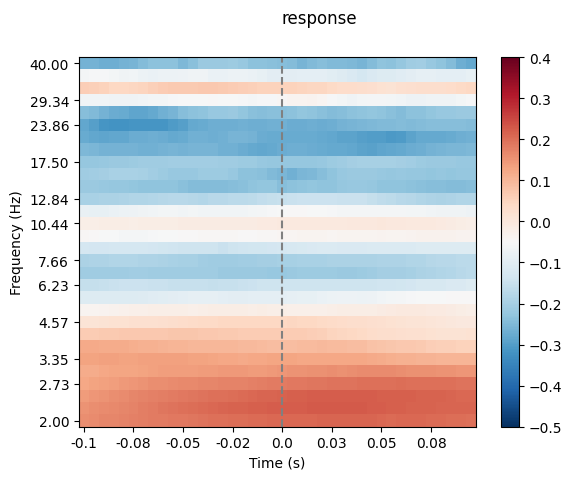

In [8]:
#parameters
channels = ['CPz']                                                      #channels to be plotted
events = ['null', 'encoding', 'decision', 'confirmation', 'response']   #event labels
z_axis = (-0.5, 0.4)

#plot total TFR
tfr.plot(picks=channels, tmin=-0.2, tmax=1, vlim=z_axis, title="Total TFR") #indicate stimulus onset


#plot single events
for n, event in enumerate(tfr_events):
    if np.any(~np.isnan(event._data)):
        AvT.plot_tfr_event(event, channels, events[n], z_axis)